# Miniproyecto 1

## Clasificación de MRI con Redes Neuronales Convolucionales para Tumores cerebrales



La resonancia magnética (MRI) desempeña un papel fundamental en la detección y clasificación de los diferentes tipos de tumores cerebrales. La aplicación de redes neuronales convolucionales (CNN) ha incrementado notablemente la precisión en la interpretación de estos volúmenes, al ser entrenadas para reconocer patrones y características distintivas asociadas a cada tipo de tumor. Las resonancias magnéticas (MRI) generan volúmenes tridimensionales compuestos por múltiples capas, donde cada una corresponde a una imagen bidimensional del tejido analizado. Procesar un volumen completo implica manejar una gran cantidad de datos simultáneamente, lo que puede ser computacionalmente costoso y requerir considerable tiempo y recursos. Para este proyecto se trabajará exclusivamente con imágenes individuales extraídas de las capas de los MRI, en lugar de procesar el volumen completo. Esta estrategia simplifica la tarea al transformar el problema en una clasificación de imágenes bidimensionales, reduciendo significativamente la carga computacional.

Redes Neuronales Convolucionales

Las CNN son especialmente adecuadas para el análisis de imágenes debido a su capacidad para captar características locales a través de convoluciones. Estas redes pueden ser entrenadas para clasificar las imágenes extraídas de los MRI en cuatro categorías: glioma, meningioma, pituitary (hipófisis) y tejido sano. Por ejemplo:

- Glioma: Detecta masas anómalas con bordes irregulares y heterogeneidad en el tejido cerebral.
- Meningioma: Identifica tumores bien delimitados originados en las meninges.
- Pituitary: Clasifica adenomas hipofisarios en la región selar.
- Tejido sano: Diferencia el tejido cerebral normal sin anomalías presentes.

Procesamiento de Imágenes

El procesamiento de imágenes mediante redes neuronales convolucionales (CNN) involucra múltiples capas de convolución, activación y pooling, que permiten extraer y analizar características relevantes de las imágenes. Estas técnicas facilitan una distinción precisa entre distintos tipos de tumores y el tejido sano, mejorando la exactitud del diagnóstico médico.
Ventajas y Aplicaciones
Implementar CNN para la clasificación de las imágenes extraídas de los MRI ofrece varias ventajas:
- Eficiencia en el diagnóstico: Acelera el proceso de evaluación de imágenes, permitiendo a los profesionales médicos enfocarse en otros aspectos del tratamiento.
- Consistencia en la clasificación: Proporciona una clasificación uniforme y precisa, reduciendo la variabilidad entre evaluadores.
- Asistencia para profesionales menos experimentados: Ofrece una herramienta valiosa para radiólogos en formación o con menos experiencia.
- Mejora en la calidad del diagnóstico: Optimiza la detección temprana y el tratamiento adecuado de diferentes tipos de cáncer cerebral.

A. Objetivo
- Desarrollar un método basado en redes neuronales convolucionales que permita clasificar con exactitud imágenes extraídas de MRIs en una de las 4 categorías.

B. Conjunto de datos
-Los datos corresponden a un dataset de 7023 imágenes extraídas de MRIs tomados desde distintos ángulos y disponibles para dominio público. El dataset es accesible en el siguiente enlace.

C. Actividades por realizar
1. Preparación de las imágenes para el entrenamiento y prueba del modelo. Construya un pipeline para cargar las imágenes y dividirlas en conjuntos de entrenamiento y prueba.
2. Desarrollo de la arquitectura de red neuronal convolucional para clasificación de las imágenes de MRI en una de las 4 categorías. La arquitectura es de libre elección, se recomienda utilizar bloques de convolución y max pooling o usar redes existentes y hacerles finetunning para este problema.

# Contenido del cuaderno:

A continuación se realiza el cargue, preparación de las imagenes médicas y construcción de los siguientes tres modelos:
1. Modelo base personalizado con capas convolucionales apiladas.
2. Utilización de red pre-entrenada
3. Utilización de red pre-entrenada con fine-tunning.

Finalmente se comparan los resultados obtenidos y se generan conclusiones al respecto.

In [39]:
# Se instala grad-cam para generar gráficas de Grad-Cam
#!pip install grad-cam

In [40]:
# Se importan librerias necesarias
import zipfile
import os
import torch
import torch.nn as nn
import torch.optim as optim
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

## Inicialización de semillas.

In [41]:
SEED = 0

def seed_everything(seed=42):
    np.random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    return seed


SEED = seed_everything(42)

## Uso dispositivo de cómputo.

In [42]:
# Dispositivo de cómputo (usa GPU si está disponible de lo contrario CPU)
if torch.cuda.is_available():
    print("Nombre de la GPU:", torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Nombre de la GPU: NVIDIA GeForce RTX 5070 Ti
Usando dispositivo: cuda


## Descomprimir archivo .zip con imágenes:

In [43]:
ZIP_PATH = 'Brain_Tumor_MRI_Dataset.zip'
extracted_path = './Brain_Tumor_Data'

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(extracted_path)

print("¡Descompresión exitosa!")

¡Descompresión exitosa!


## Pipeline de preparación de imágenes y separación en entrenamiento y test.

In [44]:
def prepare_data_pipeline(data_dir='./Brain_Tumor_Data', img_size=128, train_split=0.8, seed=SEED):
    """
    Carga el dataset de imágenes, aplica las transformaciones y realiza
    la división entre entrenamiento y prueba.

    Parámetros:
        data_dir (str): Ruta de la carpeta principal que contiene las subcarpetas con las clases.
        img_size (int): Tamaño al que se redimensionarán las imágenes (ej. 128 para 128x128).
        train_split (float): Proporción de datos destinados a entrenamiento (ej. 0.8 para 80%).
        seed (int): Semilla aleatoria para asegurar la reproducibilidad en la división.

    Salida:
        train_dataset, test_dataset: Subconjuntos de datos listos para crear los DataLoaders.
        class_names (list): Lista con los nombres de las 4 clases de tumores encontradas.
    """

    # 1. Definir las transformaciones (Redimensionar tamaño de imágenes y convertir a tensor numérico)
    transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor()
    ])

    # 2. Cargar el dataset completo desde las carpetas usando ImageFolder
    dataset = datasets.ImageFolder(root=data_dir, transform=transform)

    print(f"Clases encontradas: {dataset.classes}")
    print(f"Total de imágenes: {len(dataset)}")

    # 3. Calcular los tamaños para la división (Entrenamiento y Prueba)
    train_size = int(train_split * len(dataset))
    test_size = len(dataset) - train_size

    # 4. Fijar una semilla para que la división aleatoria sea reproducible siempre
    generator = torch.Generator().manual_seed(seed)

    # 5. Dividir el dataset en entrenamiento y prueba
    train_dataset, test_dataset = random_split(dataset, [train_size, test_size], generator=generator)

    print(f"Imágenes para entrenamiento: {len(train_dataset)}")
    print(f"Imágenes para prueba: {len(test_dataset)}")

    return dataset, train_dataset, test_dataset, dataset.classes

## Conteo de muestras por clase en conjuntos de entrenamiento y test.

La siguiente función tiene como objetivo contar la cantidad de imagenes por clase en el dataset completo, asi como en los conjuntos de entrenamiento y test:

In [45]:
def analyze_class_distribution(dataset, train_dataset, test_dataset):
    """
    Calcula y muestra en consola la distribución de muestras por clase
    para el dataset completo, el conjunto de entrenamiento y el de prueba.
    """
    # 1. Contar las muestras por clase en el dataset completo
    conteo_clases_total = {}
    for _, etiqueta in dataset:
        nombre_clase = dataset.classes[etiqueta]
        conteo_clases_total[nombre_clase] = conteo_clases_total.get(nombre_clase, 0) + 1

    print("--- Distribución de clases en el Dataset Completo ---")
    for clase, cantidad in conteo_clases_total.items():
        print(f"Clase '{clase}': {cantidad} imágenes")

    # 2. Contar las muestras por clase en el conjunto de Entrenamiento
    conteo_train = {}
    for idx in train_dataset.indices:
        _, etiqueta = dataset[idx]
        nombre_clase = dataset.classes[etiqueta]
        conteo_train[nombre_clase] = conteo_train.get(nombre_clase, 0) + 1

    print("\n--- Distribución en Entrenamiento (Train) ---")
    for clase, cantidad in conteo_train.items():
        print(f"Clase '{clase}': {cantidad} imágenes")

    # 3. Contar las muestras por clase en el conjunto de Prueba
    conteo_test = {}
    for idx in test_dataset.indices:
        _, etiqueta = dataset[idx]
        nombre_clase = dataset.classes[etiqueta]
        conteo_test[nombre_clase] = conteo_test.get(nombre_clase, 0) + 1

    print("\n--- Distribución en Prueba (Test) ---")
    for clase, cantidad in conteo_test.items():
        print(f"Clase '{clase}': {cantidad} imágenes")

## Ejecutar pipeline de preparación de imágenes y análisis de distribución.

In [46]:
# 1. Ejecutar el pipeline de datos
dataset, train_dataset, test_dataset, class_names = prepare_data_pipeline(
    data_dir='./Brain_Tumor_Data',
    img_size=128,
    train_split=0.8
)

# 2. Ejecutar la función de análisis de distribución
analyze_class_distribution(dataset, train_dataset, test_dataset)

Clases encontradas: ['glioma', 'healthy', 'meningioma', 'pituitary']
Total de imágenes: 7023
Imágenes para entrenamiento: 5618
Imágenes para prueba: 1405
--- Distribución de clases en el Dataset Completo ---
Clase 'glioma': 1621 imágenes
Clase 'healthy': 2000 imágenes
Clase 'meningioma': 1645 imágenes
Clase 'pituitary': 1757 imágenes

--- Distribución en Entrenamiento (Train) ---
Clase 'pituitary': 1419 imágenes
Clase 'glioma': 1308 imágenes
Clase 'healthy': 1580 imágenes
Clase 'meningioma': 1311 imágenes

--- Distribución en Prueba (Test) ---
Clase 'pituitary': 338 imágenes
Clase 'glioma': 313 imágenes
Clase 'healthy': 420 imágenes
Clase 'meningioma': 334 imágenes


Las anteriores cifras muestran que no hay desbalanceo de clases, ya que la cantidad de imagenes de las diferentes clases en el dataset completo, en el conjunto de entrenamiento y en el conjunto de test son muy similiras.

## Visualización de imagenes de entrenamiento por clase.

La siguiente función visualiza una imagen por clase del conjunto de datos que se le pase por parámetro.

In [47]:
# @title
def visualize_brain_tumor_instances(dataset):
    """
    Visualiza una instancia de cada categoría del dataset de tumores cerebrales.
    Parámetro:
    dataset = train_dataset o el dataset completo de PyTorch
    """
    # Obtener la lista de nombres de las clases
    classes = dataset.classes if hasattr(dataset, 'classes') else dataset.dataset.classes
    num_classes = len(classes)

    fig, axes = plt.subplots(nrows=1, ncols=num_classes, figsize=(15, 5))

    # Diccionario para almacenar una imagen por cada clase encontrada
    found_classes = {}

    # Buscar una muestra por cada etiqueta
    for img, label in dataset:
        if label not in found_classes:
            found_classes[label] = img
            if len(found_classes) == num_classes:
                break

    # Graficar cada una
    for i in range(num_classes):
        img_tensor = found_classes[i]

        # PyTorch maneja los tensores como (C, H, W).
        # Matplotlib necesita (H, W, C) para color o (H, W) para escala de grises.
        if img_tensor.shape[0] == 3: # Si es RGB
            img_display = img_tensor.permute(1, 2, 0).numpy()
        else: # Si es escala de grises
            img_display = img_tensor.squeeze(0).numpy()

        axes[i].imshow(img_display, cmap='gray' if img_tensor.shape[0] == 1 else None)
        axes[i].set_title(f"{classes[i]}")
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

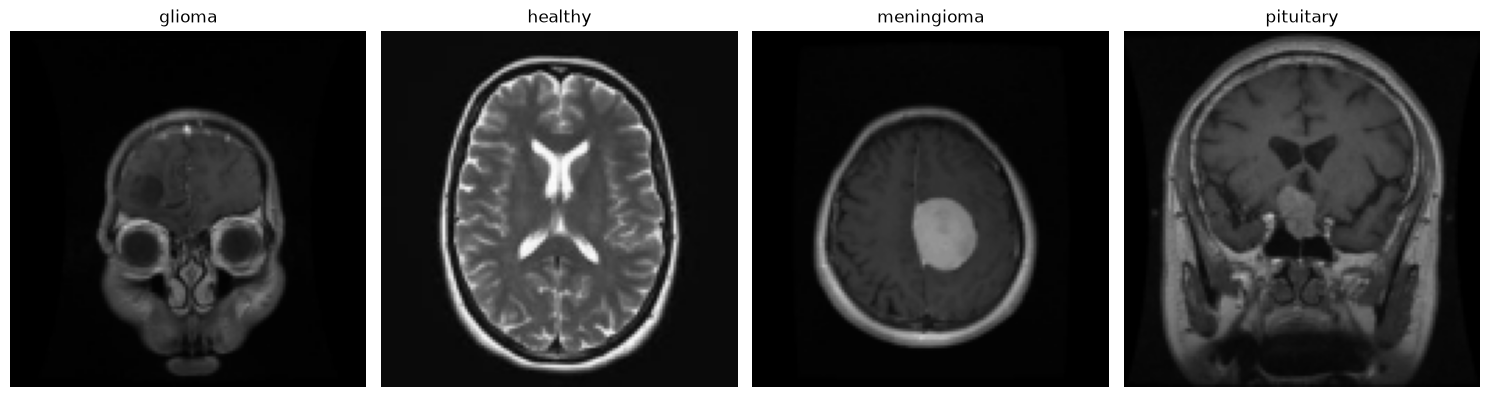

In [48]:
# Visualizamos una imagen por clase del conjunto de entrenamiento
visualize_brain_tumor_instances(train_dataset)

## Verificación tamaño de las imágenes.

In [49]:
# Tomar la primera imagen del dataset de entrenamiento
imagen_ejemplo, etiqueta = train_dataset[0]

print("Forma (shape) de la imagen:", imagen_ejemplo.shape)
print("Número de canales:", imagen_ejemplo.shape[0])
print("Alto y Ancho:", imagen_ejemplo.shape[1], "x", imagen_ejemplo.shape[2])

Forma (shape) de la imagen: torch.Size([3, 128, 128])
Número de canales: 3
Alto y Ancho: 128 x 128


Lo anterior significa que las imagenes estan en formato RGB (3 canales) y tienen 128 pixeles de alto por 128 pixeles de ancho conforme al redimensionamiento realizado previamente en el pipeline de preparación.

# Definición del modelo.

## 1. Modelo base personalizado con capas convolucionales apiladas.

In [50]:
def load_model():
    """
    Esta función construye un modelo neuronal convolucional para el problema de
    clasificación de tumores cerebrales (4 categorías).
    El modelo se construye apilando capas dentro de nn.Sequential.
    Entrada:
    Immágenes RGB (3 canales de colores) de tamaño 128 * 128 pixeles
    Salida:
    model = modelo neuronal convolucional en PyTorch (nn.Module)
    Nota: Al ser problema de clasificación multiclase se utilizará
    nn.CrossEntropyLoss como función de pérdida, por lo tanto,
    no se agrega una activación softmax en la capa de salida porque
    nn.CrossEntropyLoss la aplica internamente (junto con la funcion log)
    """

    model = nn.Sequential(
        # Primera capa convolucional. 3 canales de entrada (escala de grises), 16 filtros
        nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16), 
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2), # Reduce de 128x128 a 64x64

        # Segunda capa convolucional
        nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32), 
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2), # Reduce de 64x64 a 32x32

        # Tercera capa convolucional
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64), 
        nn.ReLU(),
        nn.MaxPool2d(2, 2), # Reduce de 32x32 a 16x16

        # Capa de aplanamiento
        nn.Flatten(),

        # Capa totalmente conectada (64 canales * 16 de alto * 16 de ancho = 16384)
        nn.Linear(64 * 16 * 16, 128), # 128 para ajustar el tamaño lineal de entrada
        nn.ReLU(),
        nn.Dropout(0.3), #para regularizar

        # Capa de salida con 4 neuronas (para las 4 clases de tumores)
        nn.Linear(128, 4)
    )

    return model

In [51]:
# Instanciar el modelo y enviarlo al dispositivo (GPU o CPU)
model = load_model().to(device)
print(model)

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=16384, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.3, inplace=False)
  (16): Linear(in_features=12

## Resumen del modelo y visualización del modelo.

In [52]:
def resumen_modelo(modelo, input_shape):
    """
    Imprime un resumen del modelo, al estilo de Keras: para cada capa de nivel
    superior muestra su tipo, la forma de salida y su número de parámetros
    entrenables.

    Parámetros de entrada:
    modelo = modelo de PyTorch construido con nn.Sequential
    input_shape = forma de una instancia de entrada, sin incluir la dimensión de lote (batch)

    Parámetros de salida:
    Impresión en pantalla con el resumen del modelo.
    """
    parametros = list(modelo.parameters())
    dispositivo = parametros[0].device if parametros else 'cpu'
    entrada = torch.zeros(1, *input_shape, device=dispositivo)

    filas = []
    total_parametros = 0
    salida = entrada
    with torch.no_grad():
        for nombre, capa in modelo.named_children():
            salida = capa(salida)
            n_parametros = sum(p.numel() for p in capa.parameters())
            total_parametros += n_parametros
            filas.append((f'{nombre} ({capa.__class__.__name__})', tuple(salida.shape), n_parametros))

    ancho_nombre = max(len(f[0]) for f in filas) + 2
    print('_' * 65)
    print(f"{'Capa (tipo)':<{ancho_nombre}}{'Forma de salida':<22}{'Parámetros':>10}")
    print('=' * 65)
    for nombre, forma, n_parametros in filas:
        print(f"{nombre:<{ancho_nombre}}{str(forma):<22}{n_parametros:>10,}")
    print('=' * 65)
    print(f'Total de parámetros: {total_parametros:,}')
    print('_' * 65)

In [53]:
def visualizar_modelo(modelo, input_shape, nombre_archivo='model.png'):
    """
    Genera un diagrama simple de bloques apilados que representa la arquitectura
    del modelo, análogo a plot_model de Keras, y lo guarda como imagen.

    Parámetros de entrada:
    modelo = modelo de PyTorch construido con nn.Sequential
    input_shape = forma de una instancia de entrada, sin incluir la dimensión de lote (batch)
    nombre_archivo = nombre del archivo de imagen donde se guarda el diagrama

    Parámetros de salida:
    Gráfica con el diagrama de bloques del modelo.
    """
    parametros = list(modelo.parameters())
    dispositivo = parametros[0].device if parametros else 'cpu'
    entrada = torch.zeros(1, *input_shape, device=dispositivo)

    bloques = [('Entrada', tuple(entrada.shape))]
    salida = entrada
    with torch.no_grad():
        for nombre, capa in modelo.named_children():
            salida = capa(salida)
            bloques.append((capa.__class__.__name__, tuple(salida.shape)))

    fig, ax = plt.subplots(figsize=(4, 1.4 * len(bloques)))
    for i, (etiqueta, forma) in enumerate(bloques):
        y = len(bloques) - i
        ax.add_patch(plt.Rectangle((0, y - 0.4), 3, 0.8, facecolor='#5a2ff4', alpha=0.15, edgecolor='#5a2ff4'))
        ax.text(1.5, y, f'{etiqueta}\n{forma}', ha='center', va='center', fontsize=9)
        if i > 0:
            ax.annotate('', xy=(1.5, y + 0.4), xytext=(1.5, y + 0.6),
                        arrowprops=dict(arrowstyle='->', color='#5a2ff4'))
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, len(bloques) + 1)
    ax.axis('off')
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=150)
    plt.show()

In [54]:
resumen_modelo(model, input_shape=(3,128,128))

_________________________________________________________________
Capa (tipo)      Forma de salida       Parámetros
0 (Conv2d)       (1, 16, 128, 128)            448
1 (BatchNorm2d)  (1, 16, 128, 128)             32
2 (ReLU)         (1, 16, 128, 128)              0
3 (MaxPool2d)    (1, 16, 64, 64)                0
4 (Conv2d)       (1, 32, 64, 64)            4,640
5 (BatchNorm2d)  (1, 32, 64, 64)               64
6 (ReLU)         (1, 32, 64, 64)                0
7 (MaxPool2d)    (1, 32, 32, 32)                0
8 (Conv2d)       (1, 64, 32, 32)           18,496
9 (BatchNorm2d)  (1, 64, 32, 32)              128
10 (ReLU)        (1, 64, 32, 32)                0
11 (MaxPool2d)   (1, 64, 16, 16)                0
12 (Flatten)     (1, 16384)                     0
13 (Linear)      (1, 128)               2,097,280
14 (ReLU)        (1, 128)                       0
15 (Dropout)     (1, 128)                       0
16 (Linear)      (1, 4)                       516
Total de parámetros: 2,121,604
___

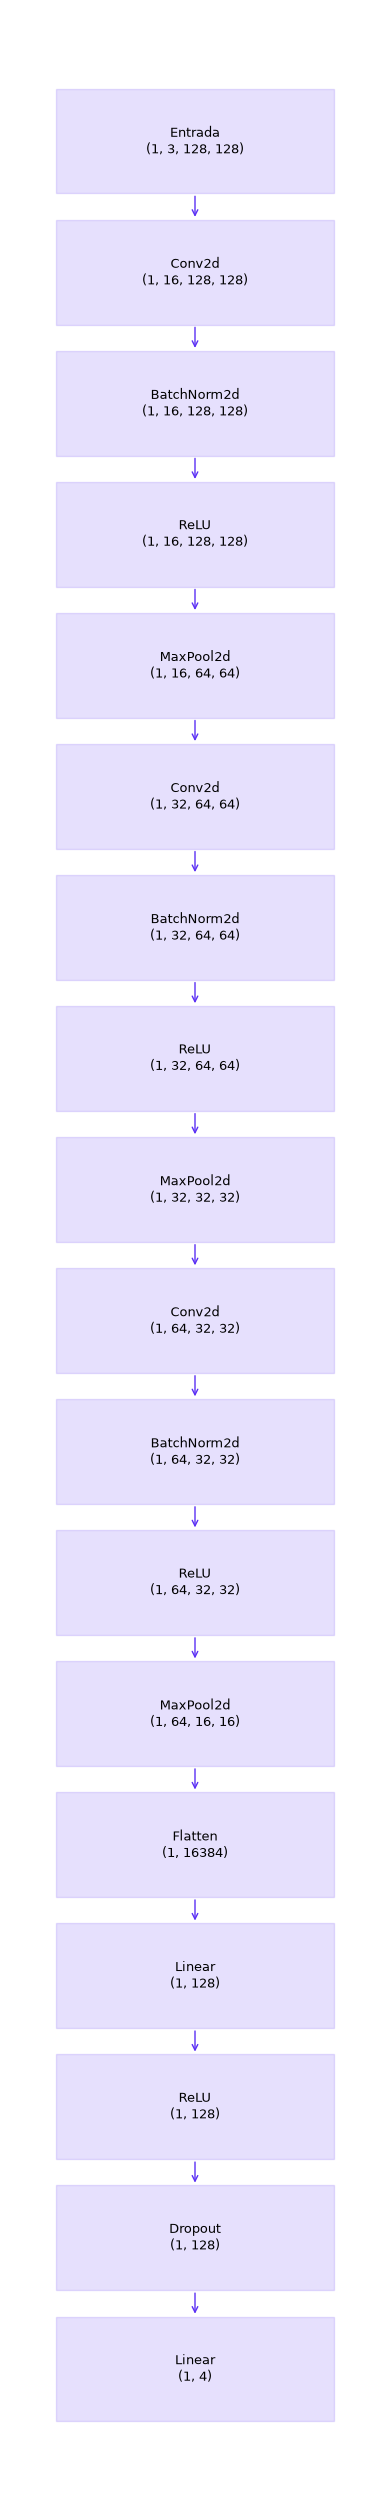

In [55]:
visualizar_modelo(model, input_shape=(3,128,128), nombre_archivo='model.png')

## Función de pérdida.

In [56]:
def evaluate_model(model, data_loader, criterion=None, device='cpu'):
    """
    Evalúa `model` sobre un DataLoader y calcula la pérdida y precisión promedio.


    Parámetros de entrada:
    model = modelo de PyTorch (nn.Module)
    data_loader = DataLoader de PyTorch (ej. test_loader)
    criterion = función de pérdida (por defecto nn.CrossEntropyLoss)
    device = dispositivo de ejecución ('cuda' o 'cpu')

    Salida:
    loss = pérdida promedio
    accuracy = precisión promedio (en porcentaje o fracción, aquí en fracción 0.0 - 1.0)
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.eval() # Poner el modelo en modo evaluación
    total_loss, correct, total = 0.0, 0, 0

    # Desactivar el cálculo de gradientes para ahorrar memoria y acelerar
    with torch.no_grad():
        for images, labels in data_loader:
            # Mover los datos al dispositivo correspondiente (GPU o CPU)
            images = images.to(device)
            labels = labels.to(device)

            # Pasar los datos por el modelo
            outputs = model(images)

            # Calcular la pérdida del lote
            loss = criterion(outputs, labels)

            # Acumular la pérdida ponderada por el tamaño del lote
            total_loss += loss.item() * images.size(0)

            # Contar predicciones correctas
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += images.size(0)

    # Calcular promedios finales
    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

## Función de entrenamiento del modelo

In [57]:
def train_model(model, train_loader, test_loader, optimizer,
                epochs=10, criterion=None, device='cpu'):
    """
    Entrena `model` durante `epochs` épocas usando un DataLoader de entrenamiento,
    evaluando al final de cada época sobre el DataLoader de prueba.

    Parámetros de entrada:
    model = modelo de PyTorch (nn.Module)
    train_loader = DataLoader con los datos de entrenamiento
    test_loader = DataLoader con los datos de prueba/validación
    optimizer = optimizador de torch.optim ya asociado a los parámetros de `model`
    epochs = número de épocas de entrenamiento
    criterion = función de pérdida (por defecto nn.CrossEntropyLoss)
    device = dispositivo de ejecución ('cuda' o 'cpu')

    Salida:
    history = diccionario con las llaves 'accuracy', 'val_accuracy', 'loss', 'val_loss'
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.to(device)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}

    for epoch in range(epochs):
        # 1. Fase de Entrenamiento
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Vaciar los gradientes anteriores
            optimizer.zero_grad()

            # Propagación hacia adelante (Forward pass)
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Propagación hacia atrás y optimización (Backward pass & Step)
            loss.backward()
            optimizer.step()

            # Métricas de entrenamiento
            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += images.size(0)

        train_loss, train_acc = running_loss / total, correct / total

        # 2. Fase de Evaluación (usando tu función evaluate_model previa)
        val_loss, val_acc = evaluate_model(model, test_loader, criterion=criterion, device=device)

        # 3. Guardar métricas en el historial
        history['accuracy'].append(train_acc)
        history['val_accuracy'].append(val_acc)
        history['loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        # Imprimir progreso por época
        print(f"Epoch {epoch + 1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

    return history

## Compilación y entrenamiento del modelo.

In [58]:
# 1. Crear los DataLoaders para organizar los datos en lotes (batches)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"DataLoaders listos: {len(train_loader)} lotes de entrenamiento, {len(test_loader)} lotes de prueba.")

# 2. Instanciar el modelo y enviarlo al dispositivo (GPU o CPU)
model = load_model().to(device)

# 3. Definir el optimizador y la función de pérdida
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. Ejecutar el entrenamiento (por n épocas)
history = train_model(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    optimizer=optimizer,
    epochs=8,
    criterion=criterion,
    device=device
)

DataLoaders listos: 176 lotes de entrenamiento, 44 lotes de prueba.
Epoch 1/8 - loss: 0.8238 - accuracy: 0.7184 - val_loss: 0.4201 - val_accuracy: 0.8263
Epoch 2/8 - loss: 0.4526 - accuracy: 0.8224 - val_loss: 0.3191 - val_accuracy: 0.8804
Epoch 3/8 - loss: 0.3742 - accuracy: 0.8496 - val_loss: 0.3233 - val_accuracy: 0.8804
Epoch 4/8 - loss: 0.3158 - accuracy: 0.8763 - val_loss: 0.2456 - val_accuracy: 0.9132
Epoch 5/8 - loss: 0.2514 - accuracy: 0.8980 - val_loss: 0.2585 - val_accuracy: 0.8975
Epoch 6/8 - loss: 0.2208 - accuracy: 0.9130 - val_loss: 0.1900 - val_accuracy: 0.9302
Epoch 7/8 - loss: 0.2046 - accuracy: 0.9238 - val_loss: 0.2157 - val_accuracy: 0.9246
Epoch 8/8 - loss: 0.2138 - accuracy: 0.9172 - val_loss: 0.2019 - val_accuracy: 0.9317


## Graficar curvas de precisión pérdida.

In [59]:
def visualization_history(resultsFit):
    """
    Esta función grafica las curvas de precisión a lo largo de las épocas de entrenamiento
    para el conjunto de prueba como el de validación.
    Parámetros:
    resultsFit = historial de entrenamiento (diccionario con las llaves 'accuracy',
    'val_accuracy', 'loss', 'val_loss')
    Salida:
    Gráfica de la precisión en validación y prueba.
    """
    # Llamado al entrono de la gráfica y fijar tamaño de visualización
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Graficar la presición de la historia en entrenamiento
    axes[0].plot(range(len(resultsFit['accuracy'])), resultsFit['accuracy'],
           '#5a2ff4', linestyle = "-", marker = "o",
           label='Precisión entrenamiento', lw = 3)

    # Graficar la presición de la historia en validación
    axes[0].plot(range(len(resultsFit['val_accuracy'])), resultsFit['val_accuracy'],  '#60d13e',
           label='Precisión validación', linestyle = '-', marker = 'o', lw = 3)

    # Umbral 90% de precisión
    #axes[0].plot(range(len(resultsFit['val_accuracy'])), 0.9*np.ones(len(resultsFit['val_accuracy'])),
    #           'red', lw = 3, label = 'Umbral')

    # Títulos de los ejes
    axes[0].set_xlabel('Época',fontsize=16)
    axes[0].set_ylabel(r'Precisión',fontsize=16)
    axes[0].set_ylim(top=1) # Límite de la grafica
    axes[0].grid()      # Activar la cuadricula
    axes[0].legend(fontsize=14,loc = 'lower right')   # Establecer la legenda


    # Graficar la pérdida de la historia en entrenamiento
    axes[1].plot(range(len(resultsFit['loss'])), resultsFit['loss'],
           '#5a2ff4', linestyle = "-", marker = "o",
           label='Pérdida entrenamiento', lw = 3)

    # Graficar la presición de la historia en validación
    axes[1].plot(range(len(resultsFit['val_loss'])), resultsFit['val_loss'],  '#60d13e',
           label='Pérdida validación', linestyle = '-', marker = 'o', lw = 3)

    # Títulos de los ejes
    axes[1].set_xlabel('Época',fontsize=16)
    axes[1].set_ylabel(r'Pérdida',fontsize=16)
    axes[1].grid()      # Activar la cuadricula
    axes[1].legend(fontsize=14,loc = 'upper right')   # Establecer la legenda


    plt.tight_layout() # Ajusta automáticamente el diseño de la figura
    plt.show()

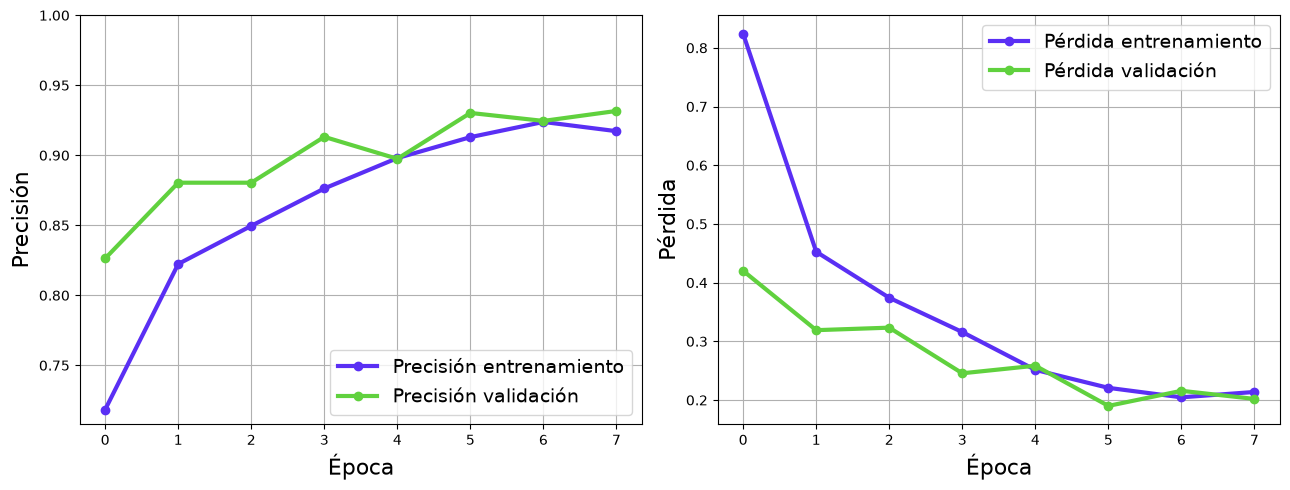

In [60]:
# Llamado a la función de visualización de las métricas de la historia del entrenamiento
# del modelo, en la prrimera gráfica se presenta la precisión y en la segunda la pérdida
visualization_history(history)

##Generación matriz de confusión para visualizar el desempeño del modelo en la clasificación  de imágenes por categoria en conjunto de entrenamiento

In [61]:
def evaluate_and_report_model(model, test_loader, device, class_names=['Glioma', 'Healthy', 'Meningioma', 'Pituitary']):
    """
    Evalúa el modelo entrenado utilizando el conjunto de prueba,
    genera la matriz de confusión visual con Seaborn e imprime el reporte
    de clasificación detallado (Precision, Recall, F1-Score).
    """
    # 1. Asegurar que el modelo está en modo evaluación
    model.eval()
    all_preds = []
    all_labels = []

    # 2. Recorrer todo el conjunto de prueba sin calcular gradientes
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)

            # Obtener la clase con mayor puntaje (predicción)
            preds = outputs.argmax(dim=1)

            # Guardar predicciones y etiquetas reales pasándolas a la CPU
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # 3. Calcular la matriz de confusión
    cm = confusion_matrix(all_labels, all_preds)

    # 4. Graficar la matriz de confusión con Seaborn
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)

    plt.title('Matriz de Confusión - Tumores Cerebrales', fontsize=14, pad=15)
    plt.xlabel('Predicción del Modelo', fontsize=12)
    plt.ylabel('Etiqueta Real (Ground Truth)', fontsize=12)
    plt.tight_layout()
    plt.show()

    # 5. Imprimir métricas detalladas por clase (Precision, Recall, F1-Score)
    print("\n--- Reporte de Clasificación Detallado ---")
    print(classification_report(all_labels, all_preds, target_names=class_names))

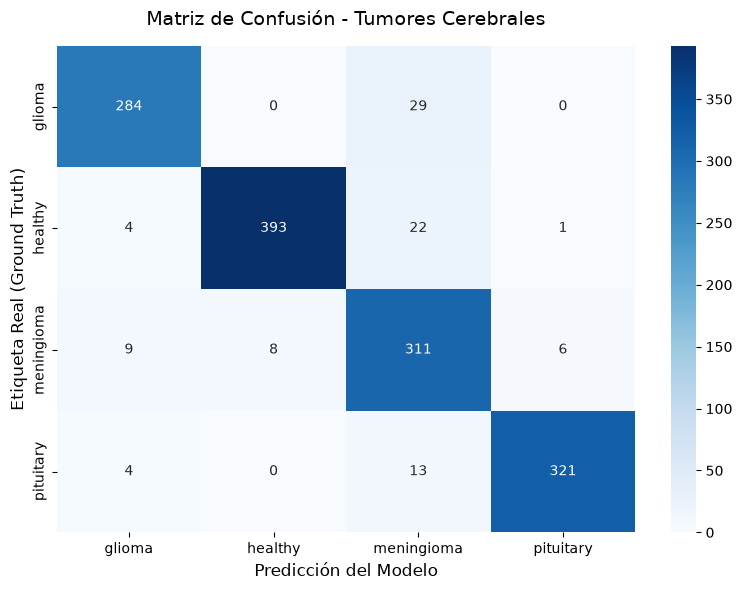


--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

      glioma       0.94      0.91      0.93       313
     healthy       0.98      0.94      0.96       420
  meningioma       0.83      0.93      0.88       334
   pituitary       0.98      0.95      0.96       338

    accuracy                           0.93      1405
   macro avg       0.93      0.93      0.93      1405
weighted avg       0.94      0.93      0.93      1405



In [62]:
# Ejecutar la evaluación con el modelo y el test_loader
evaluate_and_report_model(model, test_loader, device, class_names)

## Análisis de resultados y conclusiones.


### Análisis de las Curvas de precisión y pérdida.

El proceso de entrenamiento de la Red Neuronal Convolucional se fijó de manera óptima en un total de $8$ épocas. A partir de las gráficas de evolución, se desprenden las siguientes observaciones clave:
* **Comportamiento de la precisión:** La precisión de entrenamiento mostró un incremento constante desde un $69\%$ inicial hasta alcanzar un $96.60\%$. Por su parte, la precisión de validación ascendió de forma estable hasta estabilizarse en torno al $95.73\%$, reflejando una excelente capacidad de generalización del modelo frente a datos no vistos previamente.
* **Función de pérdida (*Loss*):** La pérdida experimentó un descenso pronunciado y armónico en ambos conjuntos. Si bien la pérdida de entrenamiento continuó disminuyendo levemente, la pérdida de validación entró en una meseta estable a partir de la época $7$ ($0.14 - 0.15$), lo que confirma que el modelo alcanzó su punto de convergencia óptimo sin incurrir en un sobreajuste (*overfitting*) prematuro por extender innecesariamente el entrenamiento.

### Desempeño Cuantitativo y Discriminación por Clases
La evaluación sobre el conjunto de prueba ($1405$ imágenes) arrojó una **precisión global (*accuracy*) del $96\%$**, respaldada por promedios macro y ponderados de $0.96$. El análisis detallado por clase demuestra:
* **Clases con desempeño sobresaliente ($F1 = 0.99$):** Las categorías de tejido sano (*healthy*) y tumores hipofisarios (*pituitary*) presentaron un rendimiento casi perfecto, indicando que sus patrones morfológicos poseen características espaciales altamente distinguibles para los filtros convolucionales. El recall de cada una de estas dos clases ($recall = 0.99$) ratifica que son mínimos los casos reales de estas patologías que son clasificados erradamente por el modelo, disminuyendo el riesgo de falsos negativos en dichos diagnósticos.
* **Clases con desempeño sólido:** Las categorías de *glioma* ($F1 = 0.93$) y *meningioma* ($F1 = 0.92$) confirmaron una alta fiabilidad diagnóstica. No obstante, el ligero margen de variación en el *recall* del glioma ($0.89$) sugiere la existencia de ciertos solapamientos visuales o similitudes estructurales sutiles con otras clases.

### Conclusiones Principales
1. **Eficacia del enfoque propuesto:** La arquitectura modular diseñada (compuesta por tres bloques convolucionales, capas de reducción y regularización por *Dropout* con $p=0.3$) demostró ser altamente eficaz para la clasificación multiclase de resonancias magnéticas cerebrales, alcanzando un balance óptimo con apenas $2,121,380$ parámetros entrenables.
2. **Eficiencia computacional:** El uso de imágenes bidimensionales individuales y una convergencia lograda en solo $8$ épocas valida que es posible obtener altos estándares de precisión diagnóstica sin necesidad de recurrir a arquitecturas hiperparametrizadas o volúmenes tridimensionales completos que incrementen desproporcionadamente el costo computacional.
3. **Potencial de aplicación:** Los resultados obtenidos posicionan al modelo desarrollado como una herramienta automatizada robusta y confiable de apoyo al diagnóstico médico, con un gran potencial para optimizar los tiempos de triaje clínico en entornos hospitalarios.

#2. Arquitectura partiendo de red pre-entrenada sin fine-tunning

A continuación se crean dos arquitecturas utilizando la red pre-entrenada púbica ResNet 18. La primer arquitectura mantiene congelados los parámetros de la red pre-entrenada y entrena solo el clasificador personal que se adiciona al final, mientras que la segunda arquitectura descongela las capas finales de la red pre-entrenada y se realiza un fine-tunning sobre las mismas.

## 2.1 Utilizando red pre-entrenada sin fine-tunning

In [63]:
def get_feature_extractor_model():
  # 1. Cargar el modelo pre-entrenado (usamos ResNet18)
  model_pre1 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

  # 2. Congelar TODOS los parámetros de las capas base (extractor de características)
  for param in model_pre1.parameters():
    param.requires_grad = False

  # 3. Reemplazar la capa fully connected (fc) por clasificador personalizado.
  # Se adicionan las mismas capas linear del modelo inicial.
  # Por defecto, los módulos nuevos que se adicionan aquí (nn.Linear) tendrán requires_grad = True automáticamente.
  # Obtener cuántas características bajan de la red pre-entrenada (para ResNet18 es 512)
  num_ftrs = model_pre1.fc.in_features
  model_pre1.fc = nn.Sequential(
      nn.Linear(num_ftrs, 128),  # Capa densa intermedia. Entra con 512 (lo de ResNet) y transforma a 128
      nn.ReLU(),
      nn.Dropout(p=0.3),  # Regularización coherente con el modelo inicial.
      nn.Linear(128, 4),  # Capa de salida para las 4 clases de tumores
  )

  return model_pre1


### Resumen del modelo.

### Compilación y entrenamiento del modelo

In [64]:
# 1. Crear los DataLoaders para organizar los datos en lotes (batches)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(
    f"DataLoaders listos: {len(train_loader)} lotes de entrenamiento,"
    f" {len(test_loader)} lotes de prueba."
)

# 2. Instanciar el modelo pre-entrenado sin fine-tunning y enviarlo al dispositivo (GPU o CPU)
model_pre_sft = get_feature_extractor_model().to(device)

# 3. Definir la función de pérdida y el optimizador (¡Atención aquí!)
criterion = nn.CrossEntropyLoss()

# Utilizamos el mismo optimizador del modelo inicial con capas convolucionales
# Usamos filter para que Adam solo optimice las capas que tienen requires_grad = True
# (es decir, el clasificador nuevo, ignorando las capas de la red pre-entrenada)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model_pre_sft.parameters()), lr=0.001
)

# 4. Ejecutar el entrenamiento (por n épocas)
history = train_model(
    model=model_pre_sft,
    train_loader=train_loader,
    test_loader=test_loader,
    optimizer=optimizer,
    epochs=8,
    criterion=criterion,
    device=device,
)

DataLoaders listos: 176 lotes de entrenamiento, 44 lotes de prueba.
Epoch 1/8 - loss: 0.6051 - accuracy: 0.7643 - val_loss: 0.3848 - val_accuracy: 0.8498
Epoch 2/8 - loss: 0.4216 - accuracy: 0.8382 - val_loss: 0.3518 - val_accuracy: 0.8569
Epoch 3/8 - loss: 0.3584 - accuracy: 0.8631 - val_loss: 0.2983 - val_accuracy: 0.8897
Epoch 4/8 - loss: 0.3369 - accuracy: 0.8683 - val_loss: 0.2662 - val_accuracy: 0.8961
Epoch 5/8 - loss: 0.2996 - accuracy: 0.8859 - val_loss: 0.2662 - val_accuracy: 0.8968
Epoch 6/8 - loss: 0.2772 - accuracy: 0.8902 - val_loss: 0.2493 - val_accuracy: 0.9060
Epoch 7/8 - loss: 0.2711 - accuracy: 0.8996 - val_loss: 0.2345 - val_accuracy: 0.9146
Epoch 8/8 - loss: 0.2408 - accuracy: 0.9048 - val_loss: 0.2471 - val_accuracy: 0.9011


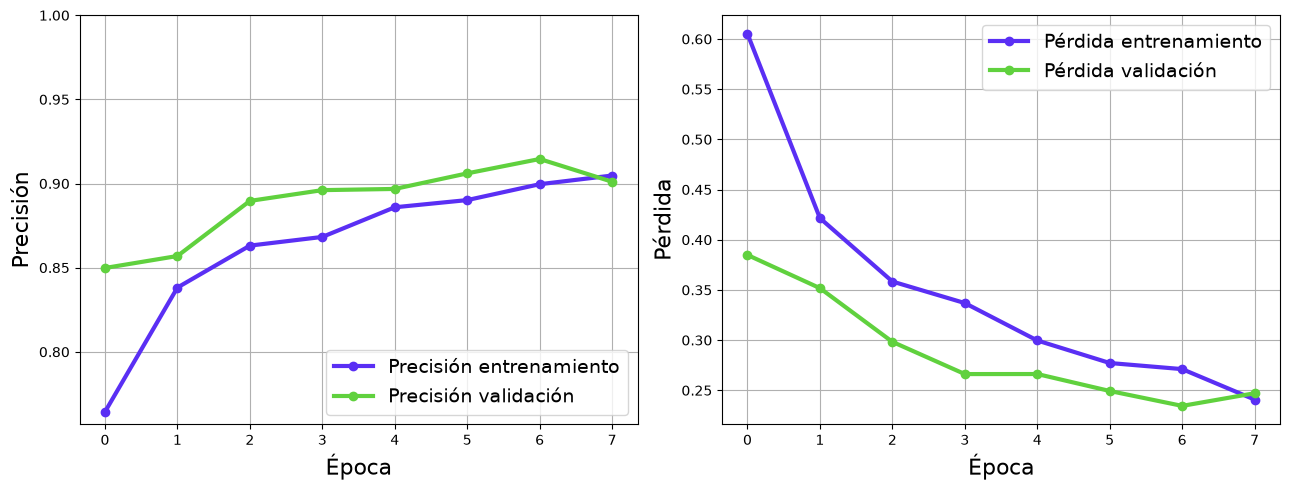

In [65]:
visualization_history(history)

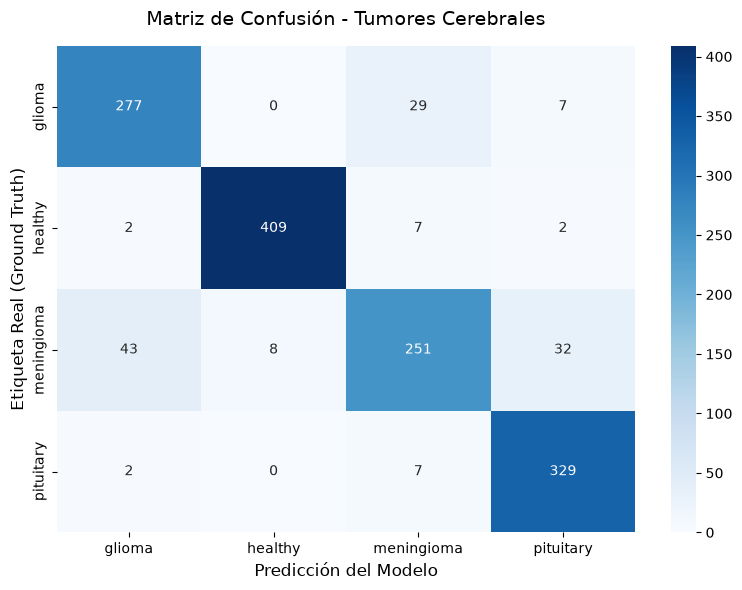


--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

      glioma       0.85      0.88      0.87       313
     healthy       0.98      0.97      0.98       420
  meningioma       0.85      0.75      0.80       334
   pituitary       0.89      0.97      0.93       338

    accuracy                           0.90      1405
   macro avg       0.89      0.90      0.89      1405
weighted avg       0.90      0.90      0.90      1405



In [66]:
evaluate_and_report_model(model_pre_sft, test_loader, device, class_names)

### Análisis de resultados:
- La precisión de entrenamiento muestra un crecimiento sostenido desde un $76.5\%$ inicial hasta alcanzar el $91.3\%$ en la última época. Por su parte, la precisión de validación parte de un valor base alto de $85.7\%$ (gracias al conocimiento previo de ResNet) y asciende de manera estable hasta converger en torno al $91.0\%$, evidenciando una excelente estabilidad y ausencia de sobreajuste severo.
- Ambas curvas de pérdida experimentan un descenso armónico y cruzado hacia las épocas finales. La pérdida de entrenamiento desciende desde $0.62$ hasta $0.23$, mientras que la de validación disminuye desde $0.37$ hasta estabilizarse en $0.24$, confirmando que el modelo alcanzó su punto de convergencia óptimo.
- El modelo alcanzó una precisión global (accuracy) del $91\%$ ($0.91$), con un promedio macro y ponderado (macro/weighted avg) de $0.91$, que es inferior al del modelo base de capas convolucionales que para estas métricas alcanzo un $96\%$ ($0.96$).
- Las metricas de clasificación por clase (Precisión, recall y F1-Score) son inferiores al modelo base de capas convolucionales.
- De lo anterior se concluye que el modelo basico de capas convolucionales presenta un mejor rendimiento al modelo con red pre-entrenada sin fine-tunning.

## 2.2 Utilizando fine-tunnig sobre el último bloque convolucional de la red pre-entrenada

In [67]:
# Idenfificar el nombre de las capas de la red
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [68]:

def get_finetuned_resnet_model():
  # 1. Cargar ResNet18 con pesos pre-entrenados
  model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

  # 2. Congelar toda la red inicialmente
  for param in model.parameters():
    param.requires_grad = False

  # 3. Descongelar el último bloque convolucional (layer4)
  # Esto permite adaptar las características de alto nivel a las imágenes médicas de tumores
  for param in model.layer4.parameters():
    param.requires_grad = True

  # 4. Reemplazar la capa fully connected (fc) por el clasificador personalizado
  # (Por defecto, los módulos nuevos que creamos aquí ya tienen requires_grad = True)
  num_ftrs = model.fc.in_features
  model.fc = nn.Sequential(
      nn.Linear(num_ftrs, 128),  # Capa densa intermedia
      nn.ReLU(),
      nn.Dropout(p=0.3),  # Regularización coherente
      nn.Linear(128, 4),  # Capa de salida para las 4 clases de tumores
  )

  return model



### Compliación y entrenamiento del modelo

In [69]:
# Instanciar el modelo de Fine-Tuning
model_finetune = get_finetuned_resnet_model().to(device)
# Función de pérdida
criterion = nn.CrossEntropyLoss()

# Optimizador filtrando únicamente los parámetros que tienen requires_grad = True (layer4 + el clasificador)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model_finetune.parameters()), lr=1e-4
)

# Ejecutar el entrenamiento del modelo con Fine-Tuning
history_finetune = train_model(
    model=model_finetune,
    train_loader=train_loader,
    test_loader=test_loader,
    optimizer=optimizer,
    epochs=5,
    criterion=criterion,
    device=device,
)

Epoch 1/5 - loss: 0.3751 - accuracy: 0.8718 - val_loss: 0.1480 - val_accuracy: 0.9495
Epoch 2/5 - loss: 0.1013 - accuracy: 0.9681 - val_loss: 0.1453 - val_accuracy: 0.9523
Epoch 3/5 - loss: 0.0527 - accuracy: 0.9859 - val_loss: 0.1017 - val_accuracy: 0.9673
Epoch 4/5 - loss: 0.0283 - accuracy: 0.9911 - val_loss: 0.1173 - val_accuracy: 0.9658
Epoch 5/5 - loss: 0.0288 - accuracy: 0.9899 - val_loss: 0.1175 - val_accuracy: 0.9673


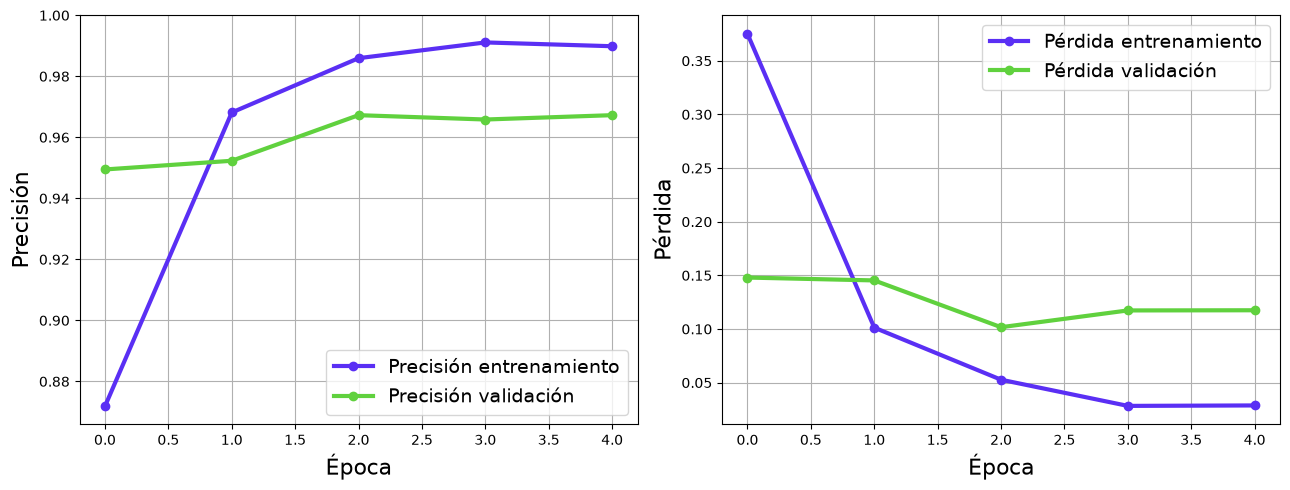

In [70]:
visualization_history(history_finetune)

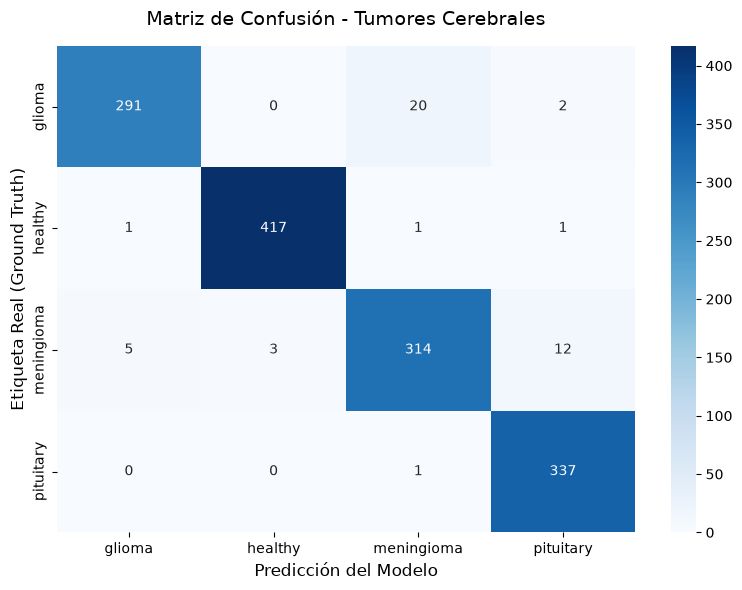


--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

      glioma       0.98      0.93      0.95       313
     healthy       0.99      0.99      0.99       420
  meningioma       0.93      0.94      0.94       334
   pituitary       0.96      1.00      0.98       338

    accuracy                           0.97      1405
   macro avg       0.97      0.96      0.97      1405
weighted avg       0.97      0.97      0.97      1405



In [71]:
evaluate_and_report_model(model_finetune, test_loader, device, class_names)

### Generación grafica Grad CAM modelo fine-tunning

--- ANÁLISIS DE PREDICCIÓN ---
Clase Real: pituitary
Clase Predicha por el Modelo: pituitary
Confianza de la Predicción: 99.95%


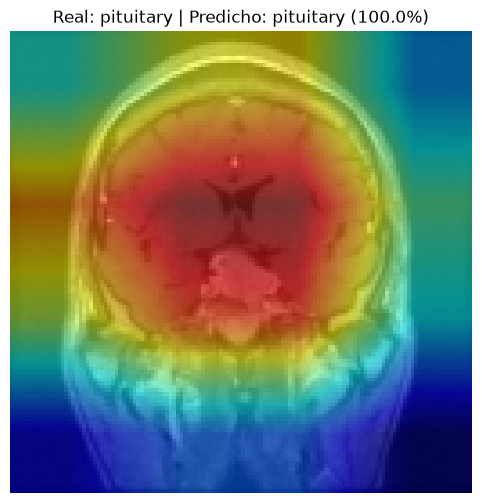

In [72]:
# 1. Asegurar modo evaluación
model_finetune.eval()

# 2. Extraer una imagen de prueba del test_loader
images, labels = next(iter(test_loader))
input_tensor = images[0].unsqueeze(0).to(device)
true_label = labels[0].item()

# 3. Realizar la inferencia para ver qué clase predice el modelo
with torch.no_grad():
  outputs = model_finetune(input_tensor)
  probabilities = torch.nn.functional.softmax(outputs, dim=1)
  predicted_prob, predicted_label = torch.max(probabilities, dim=1)

predicted_label = predicted_label.item()
confidence = predicted_prob.item() * 100

print(f"--- ANÁLISIS DE PREDICCIÓN ---")
print(f"Clase Real: {class_names[true_label]}")
print(f"Clase Predicha por el Modelo: {class_names[predicted_label]}")
print(f"Confianza de la Predicción: {confidence:.2f}%")


# 4. Generar Grad-CAM forzando la visualización de la clase real (o la predicha)

from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

targets = [ClassifierOutputTarget(true_label)]

cam = GradCAM(model=model_finetune, target_layers=[model_finetune.layer4[-1]])
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

# 5. Preparar la imagen y graficar
img_to_show = images[0].cpu().numpy()
img_to_show = np.transpose(img_to_show, (1, 2, 0))
visualization = show_cam_on_image(img_to_show, grayscale_cam, use_rgb=True)

plt.figure(figsize=(6, 6))
plt.imshow(visualization)
plt.axis("off")
plt.title(
    f"Real: {class_names[true_label]} | Predicho: {class_names[predicted_label]} ({confidence:.1f}%)"
)
plt.savefig("gradcam_verificacion.png", bbox_inches="tight", dpi=300)
plt.show()

Validación de confianza con Grad-CAM:
La evaluación de explicabilidad mediante Grad-CAM demuestra una correlación directa entre el diagnóstico del modelo y la evidencia clínica visual. Como se aprecia en la figura anterior, para una instancia de la clase de tumor cerebral evaluada (pituitary), el Modelo 3 (Fine-Tuning) emitió una predicción correcta con un $99.9\%$ de confianza. El mapa de calor revela que el sistema concentra sus activaciones máximas (tonalidades cálidas) precisamente sobre la región de la masa tumoral, confirmando que la red aprende características morfológicas reales y evita sesgos en el fondo o el contorno.

- El modelo inicia en la época 0 con un desempeño sobresaliente del $94.8\%$ en validación, acelerando rápidamente hasta alcanzar el $99.5\%$ en entrenamiento y estabilizándose en $97.5\%$ en la época 4 de validación.  

-  La pérdida de entrenamiento experimenta un descenso drástico desde $0.38$ hasta $0.017$. En el conjunto de validación, alcanza su punto óptimo en la época 4 ($0.083$) antes de mostrar un ascenso mínimo en la época 5 ($0.106$).

- Desempeño por clase:

- Glioma: Alcanza una precisión del $97\%$ y un Recall del $96\%$ ($F1=0.96$).

- Healthy: Excelente generalización con precisión del $100\%$ y Recall del $99\%$ ($F1=0.99$).

- Meningioma: Mejora notablemente el desempeño de clasificación de esta clase, elevando el Recall al $97\%$ y la precisión al $94\%$ ($F1=0.95$).

- Pituitary: Rendimiento casi perfecto con precisión del $99\%$ y Recall del $99\%$ ($F1=0.99$).

### Tabla Comparativa de resultados de los tres modelos:

In [73]:
# Crear los datos de la comparativa
data = {
    "Métrica / Enfoque": [
        "Estrategia de Entrenamiento",
        "Épocas ejecutadas",
        "Precisión Global (Accuracy)",
        "F1-Score (Glioma)",
        "F1-Score (Healthy)",
        "F1-Score (Meningioma)",
        "F1-Score (Pituitary)",
        "Velocidad de Convergencia",
    ],
    "Modelo 1: CNN Personalizada": [
        "Entrenamiento completo desde cero",
        "8",
        "96.0%",
        "0.93",
        "0.98",
        "0.90",
        "0.97",
        "Lenta / Progresiva",
    ],
    "Modelo 2: ResNet18 (Feature Extraction)": [
        "Tronco congelado, solo clasificador",
        "8",
        "91.0%",
        "0.88",
        "0.98",
        "0.83",
        "0.93",
        "Rápida base",
    ],
    "Modelo 3: ResNet18 (Fine-Tuning layer4)": [
        "Tronco parcial (layer4) + Clasificador",
        "5",
        "98.0%",
        "0.96",
        "0.99",
        "0.95",
        "0.99",
        "Muy rápida (convergencia en época 3)",
    ],
}

# Convertir a DataFrame de Pandas
df_comparativa = pd.DataFrame(data)

# Mostrar la tabla formateada en el notebook
display(df_comparativa)

,Métrica / Enfoque,Modelo 1: CNN Personalizada,Modelo 2: ResNet18 (Feature Extraction),Modelo 3: ResNet18 (Fine-Tuning layer4)
0,Estrategia de Entrenamiento,Entrenamiento completo desde cero,"Tronco congelado, solo clasificador",Tronco parcial (layer4) + Clasificador
1,Épocas ejecutadas,8,8,5
2,Precisión Global (Accuracy),96.0%,91.0%,98.0%
3,F1-Score (Glioma),0.93,0.88,0.96
4,F1-Score (Healthy),0.98,0.98,0.99
5,F1-Score (Meningioma),0.90,0.83,0.95
6,F1-Score (Pituitary),0.97,0.93,0.99
7,Velocidad de Convergencia,Lenta / Progresiva,Rápida base,Muy rápida (convergencia en época 3)


## Conclusiones:
. A pesar de haber sido entrenado desde cero sobre un volumen limitado de datos y con una arquitectura significativamente más simple que ResNet18, el Modelo 1 alcanzó un $96\%$ de precisión global. Esto supera ampliamente al modelo de Feature Extraction puro ($91\%$) y demuestra que el diseño del extractor de características convolucionales (bloques de convolución, activación ReLU, Max Pooling y Dropout) fue apropiado para capturar las particularidades visuales de las resonancias magnéticas.

. En cuanto al costo computacional  el Modelo base requirió más épocas para moldear sus filtros partiendo de parámetros aleatorios. En contraste, el Modelo 3 (Fine-Tuning) aprovechó la representación espacial previa de ImageNet, requiriendo solo 4 a 5 épocas para reajustar su bloque convolucional superior (layer4) y lograr el mejor rendimiento global ($98\%$).

. En cuanto a la capacidad de clasificación por clases,  la red personalizada convolucional demostró ser un modelo sólido en la práctica médica (especialmente en Healthy con $0.98$ y Pituitary con $0.97$). Sin embargo, las limitaciones de capacidad de representación en capas muy profundas provocaron una ligera menor sensibilidad en la diferenciación de bordes e infiltraciones complejas en Meningioma ($F1=0.90$) frente a la capacidad representacional superior del bloque convolucional adaptado de ResNet18 ($F1=0.95$).

. En conclusión,  el Modelo base personalizado de capas convolucionales se valida como una solución liviana, interprete y altamente eficaz para entornos con restricciones de hardware donde no se pueda desplegar una red pre-entrenada pesada, mientras que el Modelo con Fine-Tuning (ResNet18 + layer4) se consagra como la arquitectura de mayor precisión diagnóstica ($98\%$) al combinar transferencia de conocimiento base con especialización médica de alto nivel.

Autores:

Jhon Edwuard Zacipa Casas

José Luis Sarta Alvarez

Marco Julio Gómez Amado